In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/customers_clean.csv")

print("Dataset shape :",df.shape)
display(df.head(5))

Dataset shape : (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:

print(df["Churn"].value_counts())

print("\nPercentage distribution:")
print(
    (df["Churn"].value_counts(normalize=True) * 100).round(2)
)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Percentage distribution:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [3]:
total_customers = len(df)
churned_customers = (df["Churn"] == "Yes").sum()
churn_rate = churned_customers / total_customers*100
print("customers:",total_customers)
print("customer who churned:",churned_customers)
print(f"churn rate: {churn_rate:.2f}%")

customers: 7043
customer who churned: 1869
churn rate: 26.54%


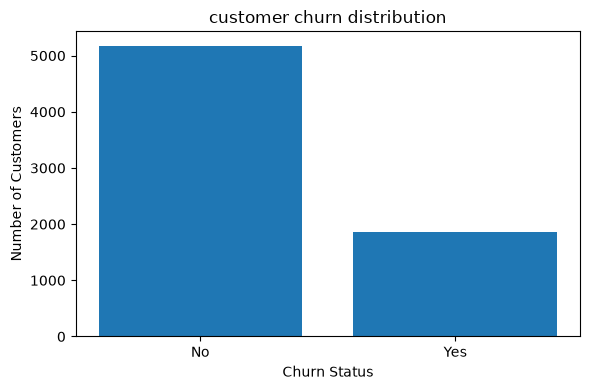

In [4]:
churn_counts = df["Churn"].value_counts()

plt.figure(figsize=(6,4))
plt.bar(churn_counts.index, churn_counts.values)
plt.title("customer churn distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [5]:

contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print(contract_churn.round(2))

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


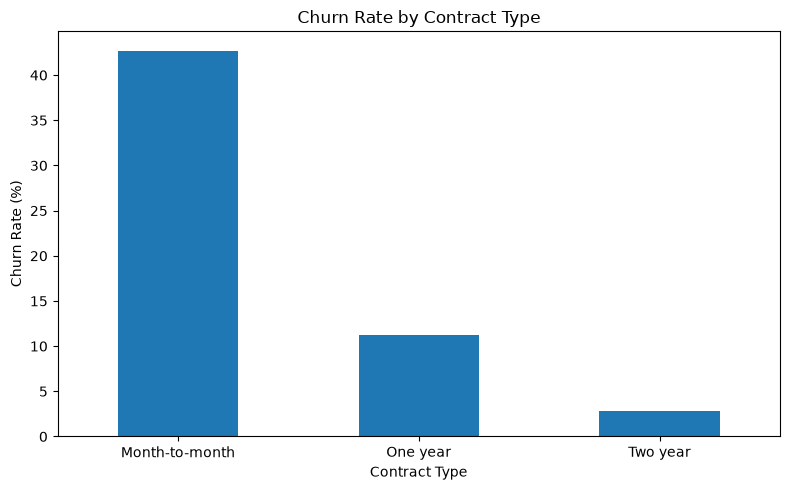

In [6]:

contract_churn.plot(kind="bar", figsize=(8, 5))

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:

charges_by_churn = (
    df.groupby("Churn")["MonthlyCharges"]
    .agg(["mean", "median", "count"])
)

print(charges_by_churn.round(2))

        mean  median  count
Churn                      
No     61.27   64.43   5174
Yes    74.44   79.65   1869


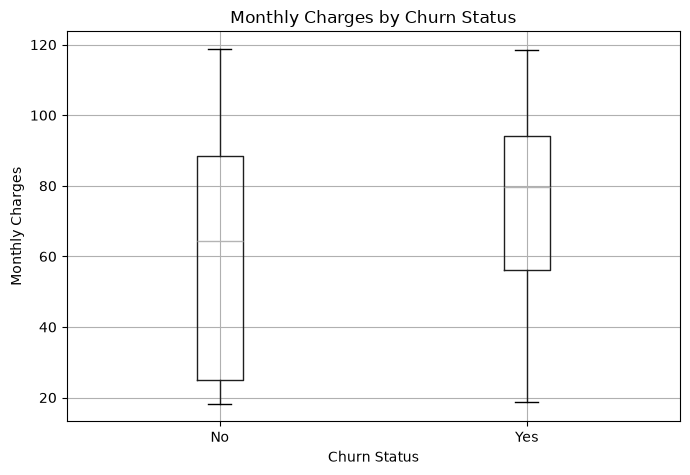

In [8]:

df.boxplot(column="MonthlyCharges", by="Churn", figsize=(7, 5))

plt.title("Monthly Charges by Churn Status")
plt.suptitle("")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

In [9]:

tenure_by_churn = (
    df.groupby("Churn")["tenure"]
    .agg(["mean", "median", "count"])
)

print(tenure_by_churn.round(2))

        mean  median  count
Churn                      
No     37.57    38.0   5174
Yes    17.98    10.0   1869


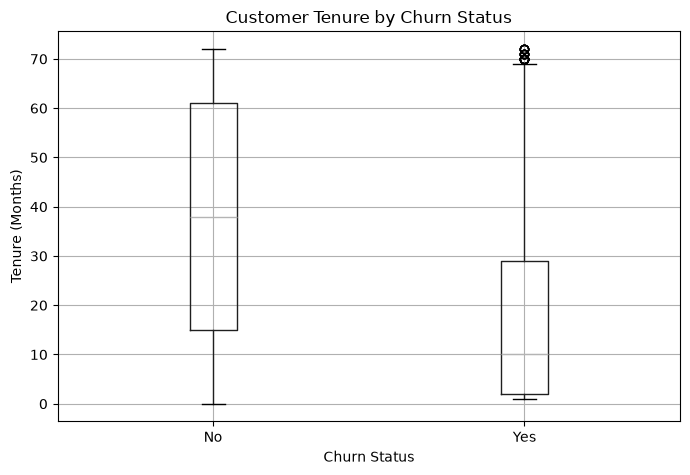

In [10]:

df.boxplot(column="tenure", by="Churn", figsize=(7, 5))

plt.title("Customer Tenure by Churn Status")
plt.suptitle("")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.show()

In [11]:

payment_churn = (
    df.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print(payment_churn.round(2))

PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64


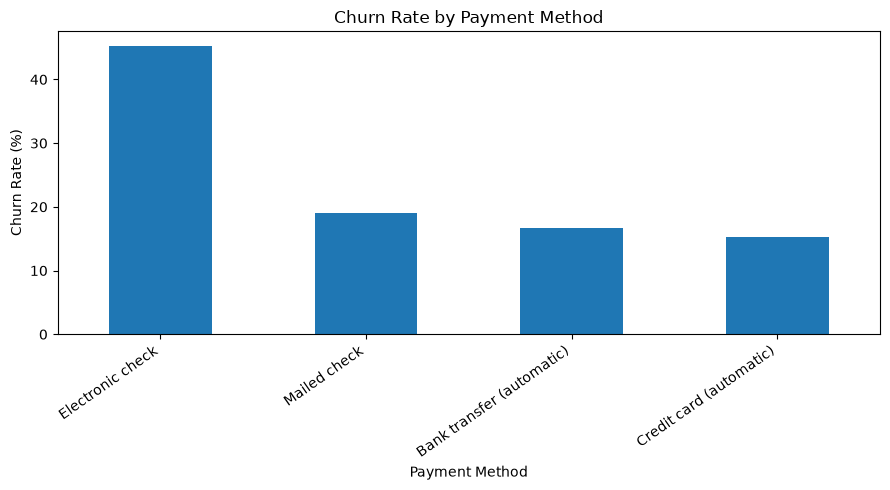

In [12]:

payment_churn.plot(kind="bar", figsize=(9, 5))

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()